# Lab 8: K-Nearest Neighbors (KNN) Classification

## Aim
Implement a K-Nearest Neighbors (KNN) classifier and study how different values of **K** and different **distance metrics** affect classification performance.

## Dataset
This lab uses the **Adult Income** dataset (`adult.csv`). The target column is `income`:
- `<=50K` — income is 50K or less.
- `>50K` — income is greater than 50K.

## What we will do
1. Load and understand the dataset.
2. Clean missing values and prepare the input features.
3. Scale numerical columns and encode categorical columns.
4. Train KNN models using different values of K.
5. Compare Euclidean, Manhattan, and Chebyshev distance metrics.
6. Evaluate the models using accuracy, precision, recall, and F1-score.
7. Visualize the results and inspect the best model's confusion matrix.

> **Note:** The original dataset contains almost 49,000 rows. To keep the lab quick enough to run on a student laptop, the experiment uses a stratified sample of 8,000 rows. The sample preserves the approximate income-class proportions. Change `SAMPLE_SIZE` to `None` in the data-preparation cell to use the full dataset (this may take longer).

## 1. Import the required libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# Keep the output tables readable.
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 120)

print('Libraries imported successfully!')

Libraries imported successfully!


## 2. Load the dataset

In [2]:
# Keep adult.csv in the same folder as this notebook.
data_path = Path('adult.csv')

if not data_path.exists():
    raise FileNotFoundError(
        "adult.csv was not found. Extract the lab ZIP file and keep adult.csv "
        "in the same folder as this notebook."
    )

df = pd.read_csv(data_path)

print('Dataset shape:', df.shape)
display(df.head())

Dataset shape: (48842, 15)


,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K


## 3. Explore the dataset

In [3]:
print('Column information:')
df.info()

print('\nIncome distribution:')
display(df['income'].value_counts().to_frame('Number of records'))

print('\nMissing or unknown values (shown as ?):')
print((df == '?').sum().sort_values(ascending=False).head(10))

Column information:
<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   age              48842 non-null  int64
 1   workclass        48842 non-null  str  
 2   fnlwgt           48842 non-null  int64
 3   education        48842 non-null  str  
 4   educational-num  48842 non-null  int64
 5   marital-status   48842 non-null  str  
 6   occupation       48842 non-null  str  
 7   relationship     48842 non-null  str  
 8   race             48842 non-null  str  
 9   gender           48842 non-null  str  
 10  capital-gain     48842 non-null  int64
 11  capital-loss     48842 non-null  int64
 12  hours-per-week   48842 non-null  int64
 13  native-country   48842 non-null  str  
 14  income           48842 non-null  str  
dtypes: int64(6), str(9)
memory usage: 5.6 MB

Income distribution:


,Number of records
income,
<=50K,37155
>50K,11687



Missing or unknown values (shown as ?):
occupation         2809
workclass          2799
native-country      857
fnlwgt                0
education             0
educational-num       0
age                   0
marital-status        0
relationship          0
gender                0
dtype: int64


## 4. Clean the data and separate features and target

In this dataset, some missing categorical values are written as `?`. We convert them to proper missing values (`NaN`). The target is converted to numbers: `<=50K` becomes 0 and `>50K` becomes 1.

In [4]:
# Remove extra spaces from text columns and convert '?' into missing values.
df = df.copy()
for column in df.select_dtypes(include='object').columns:
    df[column] = df[column].str.strip()

df = df.replace('?', np.nan)

# Convert the target column into numeric labels.
df['income'] = df['income'].map({'<=50K': 0, '>50K': 1})

# Remove rows where the target is missing, if any.
df = df.dropna(subset=['income'])
df['income'] = df['income'].astype(int)

print('Shape after basic cleaning:', df.shape)
print('Target counts (0 = <=50K, 1 = >50K):')
display(df['income'].value_counts().sort_index().to_frame('Count'))

Shape after basic cleaning: (48842, 15)
Target counts (0 = <=50K, 1 = >50K):


/tmp/ipykernel_19167/1329126857.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for column in df.select_dtypes(include='object').columns:


,Count
income,
0,37155
1,11687


### Use a manageable, balanced sample

We use stratified sampling so that the proportion of the two income classes stays approximately the same as in the original dataset. This makes the experiment faster while keeping the class distribution representative.

In [5]:
SAMPLE_SIZE = 8000  # Change to None to use all rows.

if SAMPLE_SIZE is not None and len(df) > SAMPLE_SIZE:
    df, _ = train_test_split(
        df,
        train_size=SAMPLE_SIZE,
        stratify=df['income'],
        random_state=42
    )

print('Rows used for this experiment:', len(df))
print('Class proportions:')
display((df['income'].value_counts(normalize=True).sort_index() * 100).round(2).to_frame('Percentage'))

Rows used for this experiment: 8000
Class proportions:


,Percentage
income,
0,76.08
1,23.92


## 5. Split the data into training and testing sets

The training set is used to teach the model. The test set is kept separate and is used to evaluate how well the model works on unseen data.

In [6]:
X = df.drop(columns='income')
y = df['income']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print('Training rows:', X_train.shape[0])
print('Testing rows:', X_test.shape[0])
print('Number of input columns:', X_train.shape[1])

Training rows: 6400
Testing rows: 1600
Number of input columns: 14


## 6. Preprocess the features

KNN calculates distances between data points, so numerical features should be scaled. Otherwise, columns with large values can dominate the distance calculation.

- Numerical columns: fill missing values with the median, then apply standard scaling.
- Categorical columns: fill missing values with the most common value, then convert categories into numeric columns using one-hot encoding.

The preprocessing is fitted only on the training data to avoid data leakage.

In [7]:
numeric_features = X_train.select_dtypes(include=['number']).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=['number']).columns.tolist()

numeric_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('numeric', numeric_pipeline, numeric_features),
    ('categorical', categorical_pipeline, categorical_features)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print('Processed training data shape:', X_train_processed.shape)
print('Processed testing data shape:', X_test_processed.shape)
print('Preprocessing complete!')

Processed training data shape: (6400, 104)
Processed testing data shape: (1600, 104)
Preprocessing complete!


## 7. Train KNN models with different values of K and distance metrics

**K** is the number of nearest training examples used to predict the class of a new example.

We compare these distance metrics:
- **Euclidean:** straight-line distance (Minkowski distance with p = 2).
- **Manhattan:** sum of absolute differences (Minkowski distance with p = 1).
- **Chebyshev:** the largest absolute difference across the features.

We test K values of 1, 3, 5, 7, 9, 11, 15, and 21.

In [8]:
k_values = [1, 3, 5, 7, 9, 11, 15, 21]

distance_metrics = {
    'Euclidean': {'metric': 'euclidean'},
    'Manhattan': {'metric': 'manhattan'},
    'Chebyshev': {'metric': 'chebyshev'}
}

results = []
trained_models = {}

for metric_name, metric_options in distance_metrics.items():
    for k in k_values:
        knn = KNeighborsClassifier(
            n_neighbors=k,
            weights='uniform',
            n_jobs=-1,
            **metric_options
        )

        knn.fit(X_train_processed, y_train)
        y_pred = knn.predict(X_test_processed)

        results.append({
            'Distance Metric': metric_name,
            'K': k,
            'Accuracy': accuracy_score(y_test, y_pred),
            'Precision': precision_score(y_test, y_pred, zero_division=0),
            'Recall': recall_score(y_test, y_pred, zero_division=0),
            'F1-Score': f1_score(y_test, y_pred, zero_division=0)
        })

        trained_models[(metric_name, k)] = knn

results_df = pd.DataFrame(results)
print('All model results:')
display(results_df.round(4))

All model results:


,Distance Metric,K,Accuracy,Precision,Recall,F1-Score
0,Euclidean,1,0.8069,0.5979,0.5901,0.5940
1,Euclidean,3,0.8225,0.6402,0.5901,0.6141
2,Euclidean,5,0.8194,0.6374,0.5692,0.6014
3,Euclidean,7,0.8219,0.6467,0.5640,0.6025
4,Euclidean,9,0.8256,0.6595,0.5614,0.6065
5,Euclidean,11,0.8281,0.6646,0.5692,0.6132
6,Euclidean,15,0.8319,0.6792,0.5640,0.6163
7,Euclidean,21,0.8331,0.6895,0.5509,0.6125
8,Manhattan,1,0.8031,0.5890,0.5875,0.5882
9,Manhattan,3,0.8219,0.6408,0.5822,0.6101


## 8. Compare the effect of K and distance metrics

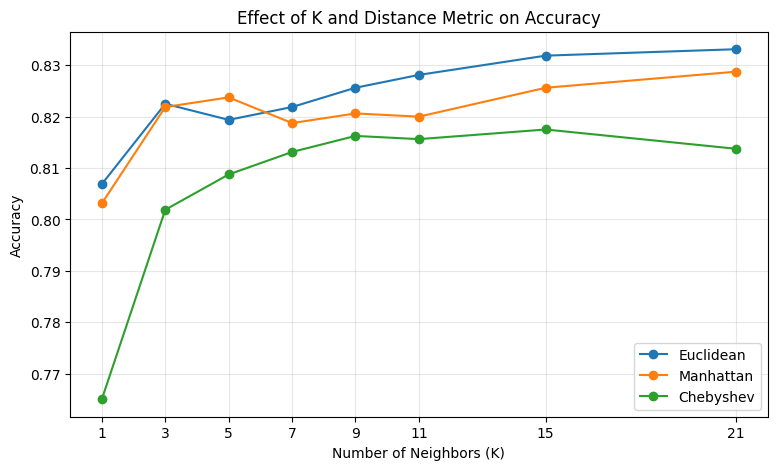

In [9]:
# Plot accuracy for each distance metric as K changes.
plt.figure(figsize=(9, 5))
for metric_name in distance_metrics:
    metric_data = results_df[results_df['Distance Metric'] == metric_name]
    plt.plot(metric_data['K'], metric_data['Accuracy'], marker='o', label=metric_name)

plt.title('Effect of K and Distance Metric on Accuracy')
plt.xlabel('Number of Neighbors (K)')
plt.ylabel('Accuracy')
plt.xticks(k_values)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

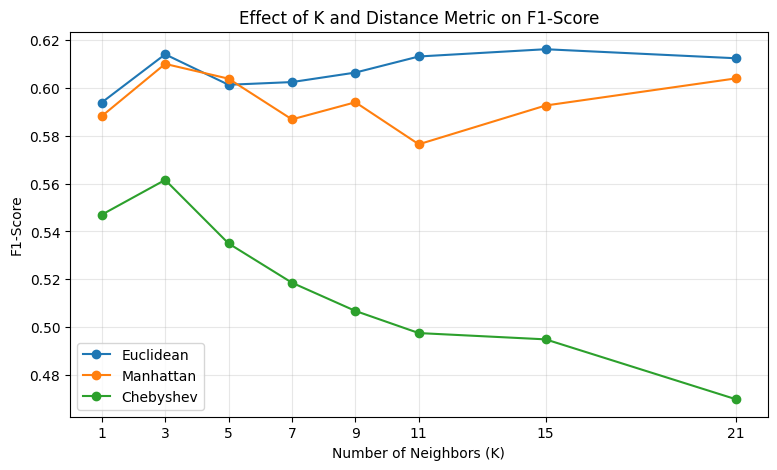

In [10]:
# F1-score balances precision and recall, so it is useful when classes are not equally represented.
plt.figure(figsize=(9, 5))
for metric_name in distance_metrics:
    metric_data = results_df[results_df['Distance Metric'] == metric_name]
    plt.plot(metric_data['K'], metric_data['F1-Score'], marker='o', label=metric_name)

plt.title('Effect of K and Distance Metric on F1-Score')
plt.xlabel('Number of Neighbors (K)')
plt.ylabel('F1-Score')
plt.xticks(k_values)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

### Average performance of each distance metric

In [11]:
metric_summary = results_df.groupby('Distance Metric')[
    ['Accuracy', 'Precision', 'Recall', 'F1-Score']
].mean().sort_values('F1-Score', ascending=False)

display(metric_summary.round(4))

,Accuracy,Precision,Recall,F1-Score
Distance Metric,,,,
Euclidean,0.8237,0.6519,0.5698,0.6076
Manhattan,0.8203,0.6482,0.5506,0.5946
Chebyshev,0.8065,0.6646,0.4370,0.5163


## 9. Select the best model

For this lab, we select the model with the highest **F1-score**. F1-score considers both precision and recall, which is helpful because the income classes are imbalanced. If two models have the same F1-score, accuracy is used as the next comparison.

In [12]:
best_row = results_df.sort_values(
    by=['F1-Score', 'Accuracy'],
    ascending=False
).iloc[0]

best_metric = best_row['Distance Metric']
best_k = int(best_row['K'])
best_model = trained_models[(best_metric, best_k)]

print('Best model configuration:')
print('Distance metric:', best_metric)
print('K:', best_k)
print('Accuracy:', round(best_row['Accuracy'], 4))
print('Precision:', round(best_row['Precision'], 4))
print('Recall:', round(best_row['Recall'], 4))
print('F1-score:', round(best_row['F1-Score'], 4))

Best model configuration:
Distance metric: Euclidean
K: 15
Accuracy: 0.8319
Precision: 0.6792
Recall: 0.564
F1-score: 0.6163
